**EXPERIMENT-2**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)

OpenCV Version: 5.0.0


In [2]:
# Load sample image
image = cv2.imread('/content/image.png')

if image is None:
    print("Image not found")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")
    plt.show()

Image not found


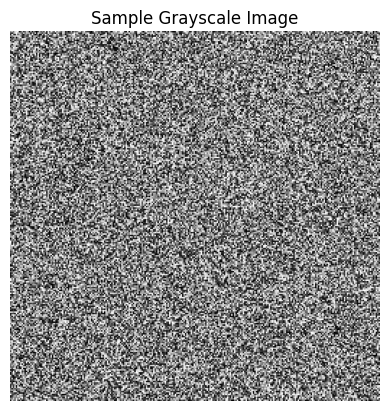

In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = np.random.randint(80, 150, (256, 256), dtype=np.uint8)

plt.imshow(image, cmap='gray')
plt.title("Sample Grayscale Image")
plt.axis("off")
plt.show()

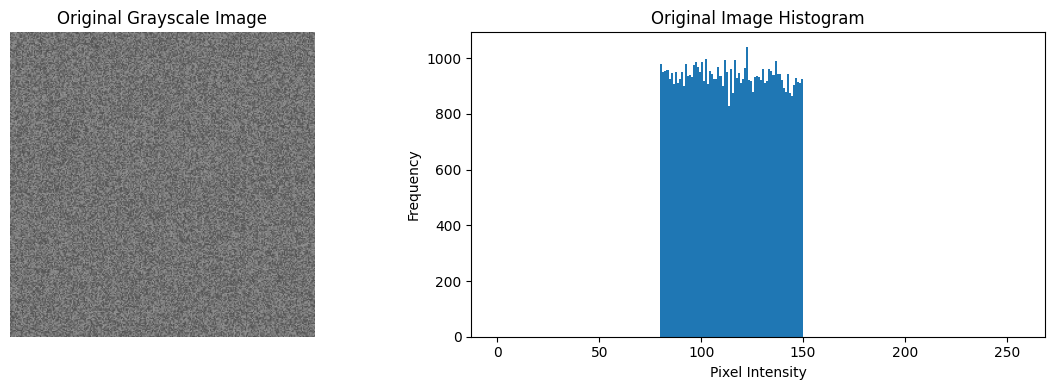

In [6]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.hist(image.ravel(), bins=256, range=(0, 256))
plt.title("Original Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

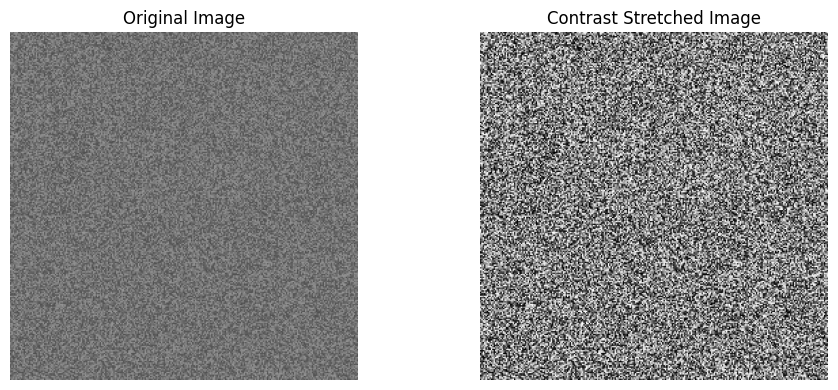

In [7]:
min_val = image.min()
max_val = image.max()

if max_val > min_val:
    stretched = (
        (image.astype(np.float32) - min_val)
        * 255 / (max_val - min_val)
    ).astype(np.uint8)
else:
    stretched = image.copy()

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(stretched, cmap='gray', vmin=0, vmax=255)
plt.title("Contrast Stretched Image")
plt.axis("off")

plt.tight_layout()
plt.show()

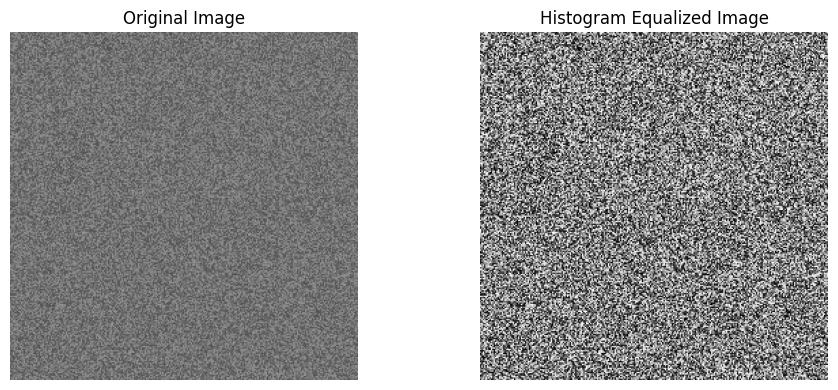

In [9]:
equalized = cv2.equalizeHist(image)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

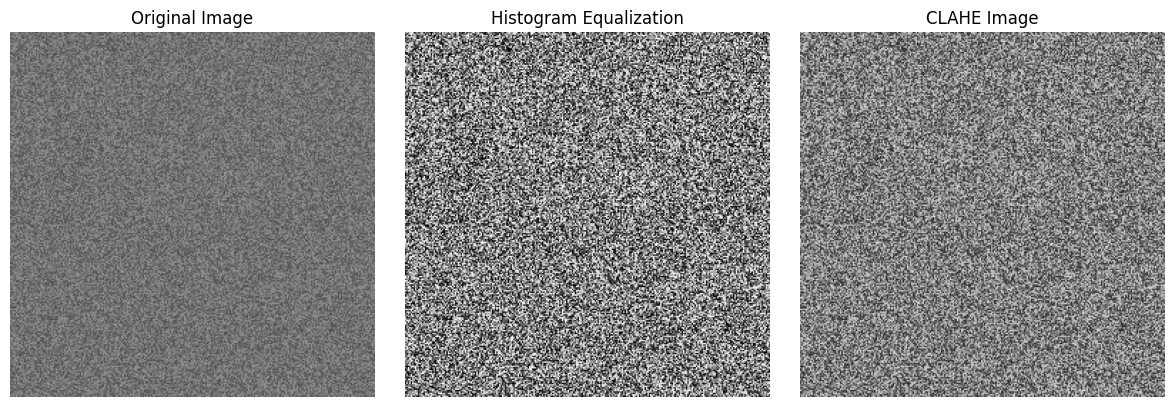

In [10]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_image = clahe.apply(image)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_image, cmap='gray', vmin=0, vmax=255)
plt.title("CLAHE Image")
plt.axis("off")

plt.tight_layout()
plt.show()

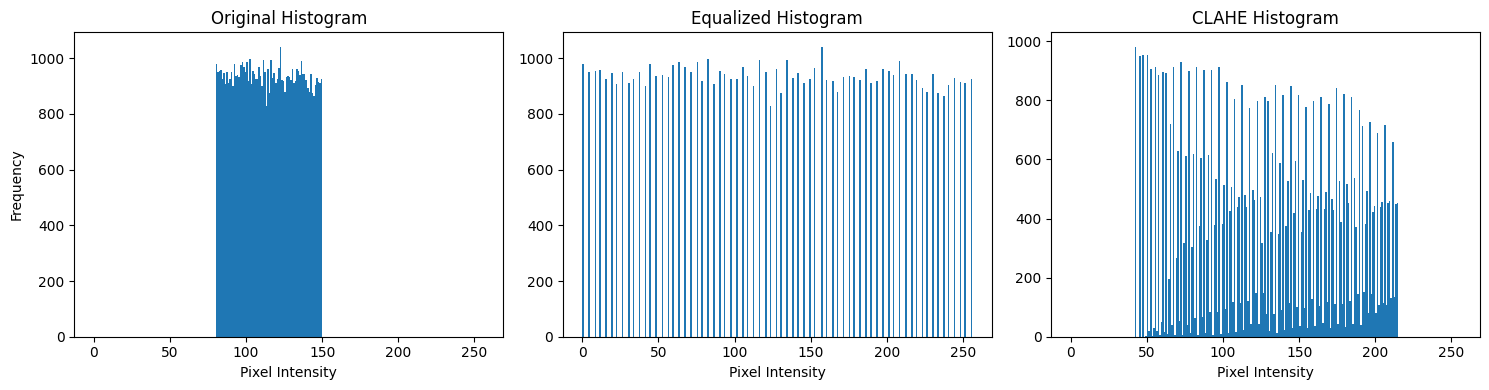

In [11]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(image.ravel(), bins=256, range=(0, 256))
plt.title("Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(1, 3, 2)
plt.hist(equalized.ravel(), bins=256, range=(0, 256))
plt.title("Equalized Histogram")
plt.xlabel("Pixel Intensity")

plt.subplot(1, 3, 3)
plt.hist(clahe_image.ravel(), bins=256, range=(0, 256))
plt.title("CLAHE Histogram")
plt.xlabel("Pixel Intensity")

plt.tight_layout()
plt.show()

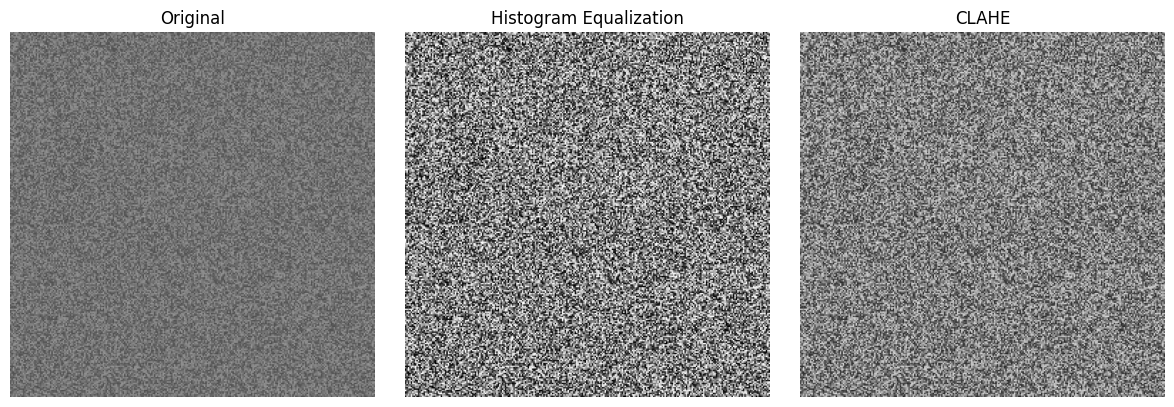

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_image, cmap='gray', vmin=0, vmax=255)
plt.title("CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
print("Original Image Range:",
      image.min(), "to", image.max())

print("Contrast Stretched Range:",
      stretched.min(), "to", stretched.max())

print("Equalized Image Range:",
      equalized.min(), "to", equalized.max())

print("CLAHE Image Range:",
      clahe_image.min(), "to", clahe_image.max())

Original Image Range: 80 to 149
Contrast Stretched Range: 0 to 255
Equalized Image Range: 0 to 255
CLAHE Image Range: 42 to 214


In [14]:
print("Experiment No. 2 Completed Successfully!")
print("Techniques used:")
print("1. Histogram Analysis")
print("2. Contrast Stretching")
print("3. Histogram Equalization")
print("4. CLAHE")

Experiment No. 2 Completed Successfully!
Techniques used:
1. Histogram Analysis
2. Contrast Stretching
3. Histogram Equalization
4. CLAHE


Questions — Answers
Q1. What is image contrast, and why is it important in image processing?
Answer: Image contrast is the difference in brightness between the light and dark regions of an image.
Importance:
- Improves image visibility.
- Makes objects and edges easier to identify.
- Helps in feature extraction and object recognition.
- Improves image analysis in computer vision applications.
Example: A low-contrast image looks faded, while a high-contrast image shows clearer differences between objects and their background.
Q2. Explain the concept of an image histogram. What information does it provide?
Answer: An image histogram is a graphical representation of the distribution of pixel intensity values in an image.
For a grayscale image, pixel intensities range from 0 to 255.
- 0: Black
- 255: White
- Intermediate values: Different shades of gray
Information provided:
1. Brightness distribution of an image.
2. Contrast level of the image.
3. Distribution of dark and bright pixels.
4. Information useful for selecting enhancement techniques.
Q3. Differentiate between Histogram Stretching and Histogram Equalization.
Histogram Stretching	Histogram Equalization
Expands the existing intensity range.	Redistributes intensities using the cumulative histogram.
Maps the minimum and maximum intensities to a wider range.	Attempts to spread pixel intensities across the available range.
Improves contrast through a relatively simple transformation.	Can improve contrast in images with concentrated intensity distributions.
Uses minimum and maximum intensity values in basic stretching.	Uses the cumulative distribution function (CDF).
Example: Histogram stretching expands a narrow intensity range, while histogram equalization redistributes intensity values based on their frequency.
Q4. What is CLAHE? How does it differ from standard Histogram Equalization?
Answer: CLAHE stands for Contrast Limited Adaptive Histogram Equalization. It is an image enhancement technique that improves local contrast by dividing an image into small regions called tiles and applying histogram equalization to each region.
Working of CLAHE:
1. Divides the image into small tiles.
2. Calculates the histogram for each tile.
3. Limits histogram contrast using a clip limit.
4. Applies histogram equalization locally.
5. Combines the tiles smoothly to reduce visible boundaries.
Difference from standard Histogram Equalization:
- Standard histogram equalization processes the image globally.
- CLAHE processes small regions independently.
- CLAHE limits contrast amplification, helping prevent excessive enhancement of noise.
- CLAHE is often more suitable for images with uneven illumination.
Q5. Why is histogram equalization commonly applied before feature extraction and image segmentation?
Answer: Histogram equalization improves image contrast by redistributing pixel intensity values. It makes important features, edges, and objects more visible.
Benefits:
- Improves feature detection.
- Makes image segmentation easier.
- Helps distinguish objects from the background.
- Can improve the accuracy of subsequent image analysis.
Q6. Mention three real-world applications where histogram equalization is widely used.
Answer: Three real-world applications are:
1. Medical imaging: Enhances details in X-rays and other medical images.
2. Satellite imaging: Improves the visibility of land, roads, and geographical features.
3. Low-light photography: Improves the visibility of details in dark images.
Q7. What are the limitations of global histogram equalization?
Answer: Global histogram equalization has the following limitations:
1. It may over-enhance some image regions.
2. It can amplify noise, especially in dark areas.
3. It does not adapt to local illumination differences.
4. It may change the overall appearance of an image.
5. It may provide poor results when different regions require different contrast adjustments.
Q8. How does contrast enhancement improve the performance of object detection and recognition systems?
Answer: Contrast enhancement improves the visibility of objects and their boundaries. This helps computer vision systems identify important features more easily.
Benefits:
- Improves edge and feature detection.
- Helps separate objects from the background.
- Makes objects more distinguishable under poor lighting.
- Can improve object detection and recognition accuracy.
Q9. Compare histogram-based enhancement techniques with brightness adjustment methods.
Histogram-Based Enhancement	Brightness Adjustment
Modifies pixel intensities based on their distribution.	Adds or subtracts a value from pixel intensities.
Mainly improves contrast.	Mainly makes the image lighter or darker.
Can reveal details in limited intensity ranges.	May not improve contrast between objects.
Examples: Histogram equalization and CLAHE.	Example: Increasing brightness by adding a constant.
Conclusion: Histogram-based techniques are useful for contrast improvement, while brightness adjustment is useful when an image is simply too dark or too bright.
Q10. Why is CLAHE preferred for medical imaging and low-light image enhancement?
Answer: CLAHE (Contrast Limited Adaptive Histogram Equalization) enhances contrast in small image regions instead of processing the entire image uniformly.
Reasons:
1. Enhances local details in different regions.
2. Handles uneven illumination effectively.
3. Limits excessive contrast amplification.
4. Can make important structures more visible.
5. Is useful for medical images and low-light photographs